# Encoders v1 checks: ink tint, buffer width, per-region scores

Reuses the features saved by `encoders_v1` (no GPU, no re-extraction). Three checks:

1. **Faint blue tint.** Some top-scoring tumor tiles looked slightly blue. If tumor tiles are bluer than benign ones,
   the model could be partly detecting leftover ink. We measure blueness per tile, see whether it alone separates the classes,
   and retrain without the bluest tiles.
2. **Buffer width.** False positives ringed the large tumor just outside the 1 mm buffer. We retrain with benign tiles
   at least 2 mm and 3 mm from any region.
3. **Per-region scores.** How each marked region scores, to see whether the top region (called benign by both models) differs.

Run order: install cell, restart, then from the mount cell. A CPU runtime is enough.

## 0. Install, then restart the session

In [ ]:
!pip install -q "imagecodecs[all]" tifffile scikit-image

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab; skipping Drive mount.')

Mounted at /content/drive


## 1. Load features and tile info

In [ ]:
import os, time, threading
import numpy as np
import pandas as pd
import tifffile, imagecodecs
import matplotlib.pyplot as plt
from functools import lru_cache
from scipy.stats import spearmanr
from skimage.color import rgb2hsv
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
from IPython.display import display

DATA_DIR  = '/content/drive/MyDrive/spring/capstone/data'
ENC_DIR   = os.path.join(DATA_DIR, 'encoders_v1')
TILES_CSV = os.path.join(DATA_DIR, 'tiles_v1', 'pt109_tile_labels.csv')
SLIDE     = os.path.join(DATA_DIR, 'pt109.ome.tif')
os.makedirs(os.path.join(ENC_DIR, 'figures'), exist_ok=True)
BLOCK_TILES = 16
SEED = 0

def save_fig(name):
    plt.savefig(os.path.join(ENC_DIR, 'figures', f'{name}.png'), dpi=150, bbox_inches='tight')

features, order = {}, None
for name, fn in [('UNI', 'pt109_uni.npz'), ('CONCH', 'pt109_conch.npz')]:
    z = np.load(os.path.join(ENC_DIR, fn), allow_pickle=True)
    features[name] = z['features'].astype(np.float32)
    if order is None:
        order = pd.DataFrame({'x0': z['x0'], 'y0': z['y0']})
info = pd.read_csv(TILES_CSV)
tiles = order.merge(info, on=['x0', 'y0'], how='left')
assert tiles.label.notna().all(), 'tile coordinates did not match tiles_v1'
tiles['y'] = (tiles.label == 'tumor').astype(int)
tiles['block'] = (tiles.gy // BLOCK_TILES).astype(str) + '_' + (tiles.gx // BLOCK_TILES).astype(str)

# distance from each tile to the nearest excluded ink tile, on the tile grid
from scipy import ndimage as ndi
grid_ink = np.zeros((info.gy.max() + 1, info.gx.max() + 1), bool)
ink = info[info.label == 'excluded_ink']
grid_ink[ink.gy, ink.gx] = True
d_ink = ndi.distance_transform_edt(~grid_ink)
tiles['dist_to_ink_tiles'] = d_ink[tiles.gy, tiles.gx]
print(f'{len(tiles)} tiles ({tiles.y.sum()} tumor), features:', {k: v.shape for k, v in features.items()})

5579 tiles (579 tumor), features: {'UNI': (5579, 1024), 'CONCH': (5579, 512)}


## 2. Shared probe
Same as `encoders_v1`: logistic regression, 5-fold spatial cross-validation on ~2 mm blocks, pooled out-of-fold scores.

In [ ]:
def probe(X, df):
    y, g = df.y.values, df.block.values
    if y.sum() < 10 or (1 - y).sum() < 10:
        return np.full(len(y), np.nan), np.nan, np.nan      # too few tiles of one class left
    k = min(5, len(np.unique(g)))
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight='balanced', max_iter=3000))
    try:
        p = cross_val_predict(clf, X, y, groups=g, cv=GroupKFold(n_splits=k), method='predict_proba')[:, 1]
    except ValueError:                                       # a training fold ended up with one class
        return np.full(len(y), np.nan), np.nan, np.nan
    return p, roc_auc_score(y, p), average_precision_score(y, p)

base = {}
for name, X in features.items():
    p, auc, ap = probe(X, tiles)
    base[name] = p
    print(f'{name}: AUC {auc:.3f}, avg precision {ap:.3f} (chance {tiles.y.mean():.3f})')

UNI: AUC 0.917, avg precision 0.655 (chance 0.104)
CONCH: AUC 0.874, avg precision 0.526 (chance 0.104)


## 3. Check 1: faint blue tint
For each tile, read at pyramid level 1 (about 1.4 µm/px):
* `faint_blue`: share of pixels with blue hue at a much lower saturation than the ink rule (0.12 instead of 0.5), so faint haze counts.
* `glass_blue`: on bright background pixels only (empty gland space, glass), how much bluer than red they are. Clean glass is near 0.

If either measure alone separates tumor from benign well (AUC far from 0.5), tint could be a shortcut.
`dist_to_ink_tiles` is shown for context only: tumor tiles sit inside ink rings, so they are closer to ink by construction.

measured 5579 tiles in 23 s


,tumor median,benign median,AUC alone (0.5 = no signal)
measure,,,
faint_blue,0.0000,0.000,0.527
glass_blue,-1.7801,-8.776,0.724
dist_to_ink_tiles,2.8284,19.105,0.056


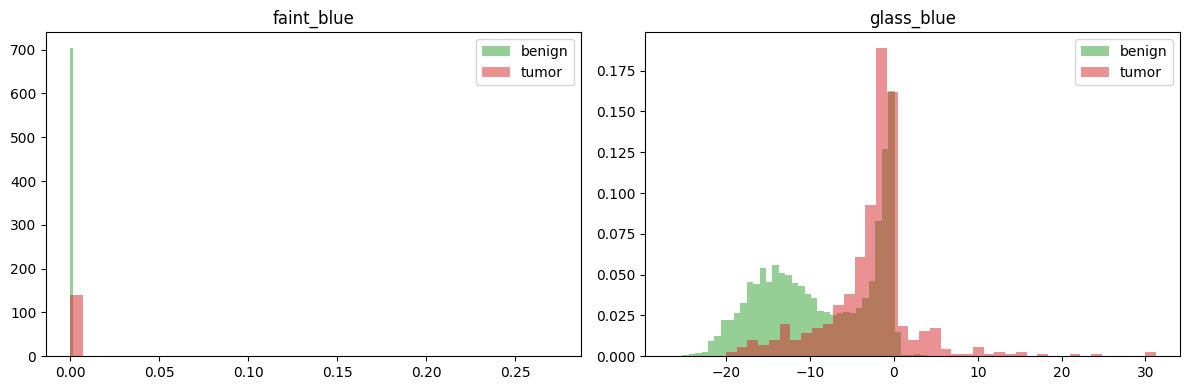

In [ ]:
def to_rgb(arr):
    arr = np.squeeze(arr)
    if arr.ndim == 2: arr = np.stack([arr] * 3, -1)
    if arr.ndim == 3 and arr.shape[0] in (3, 4) and arr.shape[-1] not in (3, 4):
        arr = np.moveaxis(arr, 0, -1)
    return np.ascontiguousarray(arr[..., :3]).astype(np.uint8)

class SlideReader:
    def __init__(self, path, level=0, cache_tiles=1024):
        self.tif = tifffile.TiffFile(path)
        levels = self.tif.series[0].levels
        self.level = min(level, len(levels) - 1)
        pg = levels[self.level].keyframe
        self.downsample = levels[0].keyframe.imagewidth / pg.imagewidth
        self.pg, self.th, self.tw = pg, pg.tilelength, pg.tilewidth
        self.ny, self.nx = -(-pg.imagelength // self.th), -(-pg.imagewidth // self.tw)
        self.offsets, self.counts = pg.dataoffsets, pg.databytecounts
        self.tile = lru_cache(maxsize=cache_tiles)(self._read_tile)

    def _read_tile(self, ty, tx):
        i = ty * self.nx + tx
        blank = np.full((self.th, self.tw, 3), 255, np.uint8)
        if i >= len(self.offsets) or self.counts[i] == 0: return blank
        self.tif.filehandle.seek(self.offsets[i]); buf = self.tif.filehandle.read(self.counts[i])
        try:
            t = imagecodecs.jpeg_decode(buf, tables=self.pg.jpegtables) if self.pg.jpegtables else imagecodecs.jpeg_decode(buf)
        except Exception:
            return blank
        t = to_rgb(t)
        if t.shape[:2] != (self.th, self.tw):
            blank[:t.shape[0], :t.shape[1]] = t[:self.th, :self.tw]; t = blank
        return t

    def read_box0(self, x0, y0, size0):
        d = self.downsample
        x, y, s = int(x0 / d), int(y0 / d), max(1, int(round(size0 / d)))
        out = np.full((s, s, 3), 255, np.uint8)
        for ty in range(max(y // self.th, 0), min((y + s - 1) // self.th, self.ny - 1) + 1):
            for tx in range(max(x // self.tw, 0), min((x + s - 1) // self.tw, self.nx - 1) + 1):
                tl = self.tile(ty, tx)
                ys0, ys1 = max(y, ty * self.th), min(y + s, (ty + 1) * self.th)
                xs0, xs1 = max(x, tx * self.tw), min(x + s, (tx + 1) * self.tw)
                out[ys0 - y:ys1 - y, xs0 - x:xs1 - x] = tl[ys0 - ty * self.th:ys1 - ty * self.th, xs0 - tx * self.tw:xs1 - tx * self.tw]
        return out

    def close(self): self.tif.close()

def tint(img):
    hsv = rgb2hsv(img)
    fb = float(((hsv[..., 0] >= 0.50) & (hsv[..., 0] <= 0.70) & (hsv[..., 1] >= 0.12) & (hsv[..., 2] >= 0.5)).mean())
    f = img.astype(np.float32)
    bright = f.min(-1) > 180
    gb = float((f[..., 2] - f[..., 0])[bright].mean()) if bright.sum() > 20 else np.nan
    return fb, gb

reader = SlideReader(SLIDE, level=1)
vals, t0 = [], time.time()
for i, r in enumerate(tiles.itertuples()):
    vals.append(tint(reader.read_box0(int(r.x0), int(r.y0), int(r.tile_px))))
reader.close()
tiles['faint_blue'], tiles['glass_blue'] = zip(*vals)
print(f'measured {len(tiles)} tiles in {time.time() - t0:.0f} s')

rows = []
for m in ['faint_blue', 'glass_blue', 'dist_to_ink_tiles']:
    ok = tiles[m].notna()
    rows.append({'measure': m,
                 'tumor median': round(tiles.loc[ok & (tiles.y == 1), m].median(), 4),
                 'benign median': round(tiles.loc[ok & (tiles.y == 0), m].median(), 4),
                 'AUC alone (0.5 = no signal)': round(roc_auc_score(tiles.y[ok], tiles[m][ok]), 3)})
display(pd.DataFrame(rows).set_index('measure'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ['faint_blue', 'glass_blue']):
    for lab, col in [(0, 'tab:green'), (1, 'tab:red')]:
        v = tiles.loc[(tiles.y == lab) & tiles[m].notna(), m]
        ax.hist(v, bins=40, density=True, alpha=0.5, color=col, label=['benign', 'tumor'][lab])
    ax.set_title(m); ax.legend()
plt.tight_layout(); save_fig('tint_distributions'); plt.show()

**Does tint drive the score?** Within tumor tiles only, does a bluer tile get a higher score?
Then: retrain without the bluest tiles (above the 95th percentile of benign `faint_blue`), and without tiles next to ink.
If the scores barely change, tint is not what the model relies on.

In [ ]:
tm = tiles.y == 1
for name, p in base.items():
    for m in ['faint_blue', 'glass_blue']:
        ok = tm & tiles[m].notna()
        rho, pv = spearmanr(tiles.loc[ok, m], p[ok.values])
        print(f'{name}: score vs {m} within tumor tiles, Spearman {rho:+.2f} (p={pv:.2g})')

thr = tiles.loc[tiles.y == 0, 'faint_blue'].quantile(0.95)
subsets = {
    'all tiles (baseline)': np.ones(len(tiles), bool),
    f'drop faint_blue > {thr:.4f}': (tiles.faint_blue <= thr).values,
    'drop tiles next to ink (≤1 tile away)': (tiles.dist_to_ink_tiles > 1).values,
}
rows = []
for sname, keep in subsets.items():
    df = tiles[keep]
    for name, X in features.items():
        _, auc, ap = probe(X[keep], df)
        rows.append({'subset': sname, 'model': name, 'tumor tiles': int(df.y.sum()), 'benign tiles': int((1 - df.y).sum()),
                     'AUC': round(auc, 3), 'avg precision': round(ap, 3), 'chance': round(df.y.mean(), 3)})
tint_results = pd.DataFrame(rows)
display(tint_results)
tint_results.to_csv(os.path.join(ENC_DIR, 'check_tint.csv'), index=False)

UNI: score vs faint_blue within tumor tiles, Spearman +0.17 (p=4e-05)
UNI: score vs glass_blue within tumor tiles, Spearman +0.21 (p=6.8e-07)
CONCH: score vs faint_blue within tumor tiles, Spearman +0.18 (p=1e-05)
CONCH: score vs glass_blue within tumor tiles, Spearman +0.18 (p=2.3e-05)


,subset,model,tumor tiles,benign tiles,AUC,avg precision,chance
0,all tiles (baseline),UNI,579,5000,0.917,0.655,0.104
1,all tiles (baseline),CONCH,579,5000,0.874,0.526,0.104
2,drop faint_blue > 0.0000,UNI,538,4910,0.922,0.662,0.099
3,drop faint_blue > 0.0000,CONCH,538,4910,0.877,0.515,0.099
4,drop tiles next to ink (≤1 tile away),UNI,462,4918,0.933,0.685,0.086
5,drop tiles next to ink (≤1 tile away),CONCH,462,4918,0.879,0.501,0.086


The bluest tumor tiles that were kept, to look at directly:

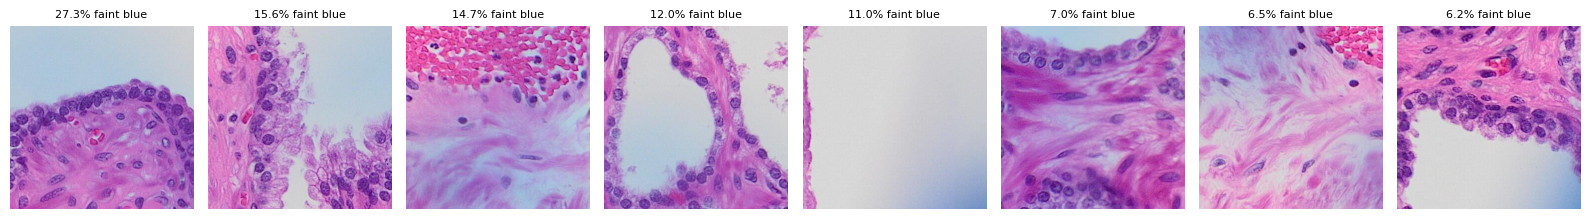

In [ ]:
reader0 = SlideReader(SLIDE, level=0)
top = tiles[tm].nlargest(8, 'faint_blue')
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, (_, r) in zip(axes, top.iterrows()):
    ax.imshow(reader0.read_box0(int(r.x0), int(r.y0), int(r.tile_px))); ax.axis('off')
    ax.set_title(f'{100 * r.faint_blue:.1f}% faint blue', fontsize=8)
reader0.close()
plt.tight_layout(); save_fig('bluest_tumor_tiles'); plt.show()

## 4. Check 2: wider buffer around tumor
Benign tiles must be at least 1 mm (current), 2 mm or 3 mm from any ink region. Tumor tiles are unchanged.
If false positives near the tumor were real tumor beyond the ink, precision should rise as the buffer widens.

,buffer,model,benign tiles,AUC,avg precision,chance
0,1 mm,UNI,5000,0.917,0.655,0.104
1,1 mm,CONCH,5000,0.874,0.526,0.104
2,2 mm,UNI,4521,0.903,0.720,0.114
3,2 mm,CONCH,4521,0.848,0.585,0.114
4,3 mm,UNI,4089,0.950,0.840,0.124
5,3 mm,CONCH,4089,0.922,0.729,0.124


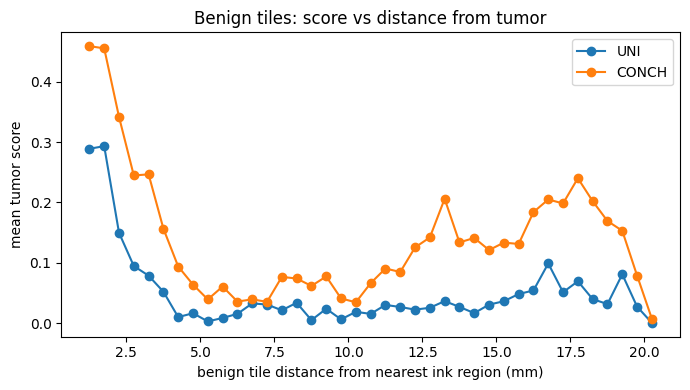

In [ ]:
rows = []
for mm in [1, 2, 3]:
    keep = ((tiles.y == 1) | (tiles.dist_to_region_um >= mm * 1000)).values
    df = tiles[keep]
    for name, X in features.items():
        _, auc, ap = probe(X[keep], df)
        rows.append({'buffer': f'{mm} mm', 'model': name, 'benign tiles': int((1 - df.y).sum()),
                     'AUC': round(auc, 3), 'avg precision': round(ap, 3), 'chance': round(df.y.mean(), 3)})
buffer_results = pd.DataFrame(rows)
display(buffer_results)
buffer_results.to_csv(os.path.join(ENC_DIR, 'check_buffer.csv'), index=False)

# where are the benign false positives? score vs distance from the tumor
fig, ax = plt.subplots(figsize=(7, 4))
b = tiles.y == 0
for name, p in base.items():
    d = tiles.loc[b, 'dist_to_region_um'] / 1000
    bins = np.arange(1, d.max() + 0.5, 0.5)
    idx = np.digitize(d, bins)
    means = [p[b.values][idx == i].mean() if (idx == i).sum() > 10 else np.nan for i in range(1, len(bins))]
    ax.plot(bins[:-1] + 0.25, means, marker='o', label=name)
ax.set_xlabel('benign tile distance from nearest ink region (mm)'); ax.set_ylabel('mean tumor score')
ax.set_title('Benign tiles: score vs distance from tumor'); ax.legend()
plt.tight_layout(); save_fig('benign_score_vs_distance'); plt.show()

## 5. Check 3: scores per marked region
Mean tumor score and share of tiles scored above 0.5, for each ink region. Region ids match `eda_v4_outputs/pt109_regions.csv`
and the ink QA figure.

,tumor tiles,UNI mean score,UNI share > 0.5,CONCH mean score,CONCH share > 0.5
region_id,,,,,
2,131,0.211,0.176,0.323,0.267
3,91,0.731,0.802,0.748,0.813
4,357,0.762,0.779,0.762,0.835


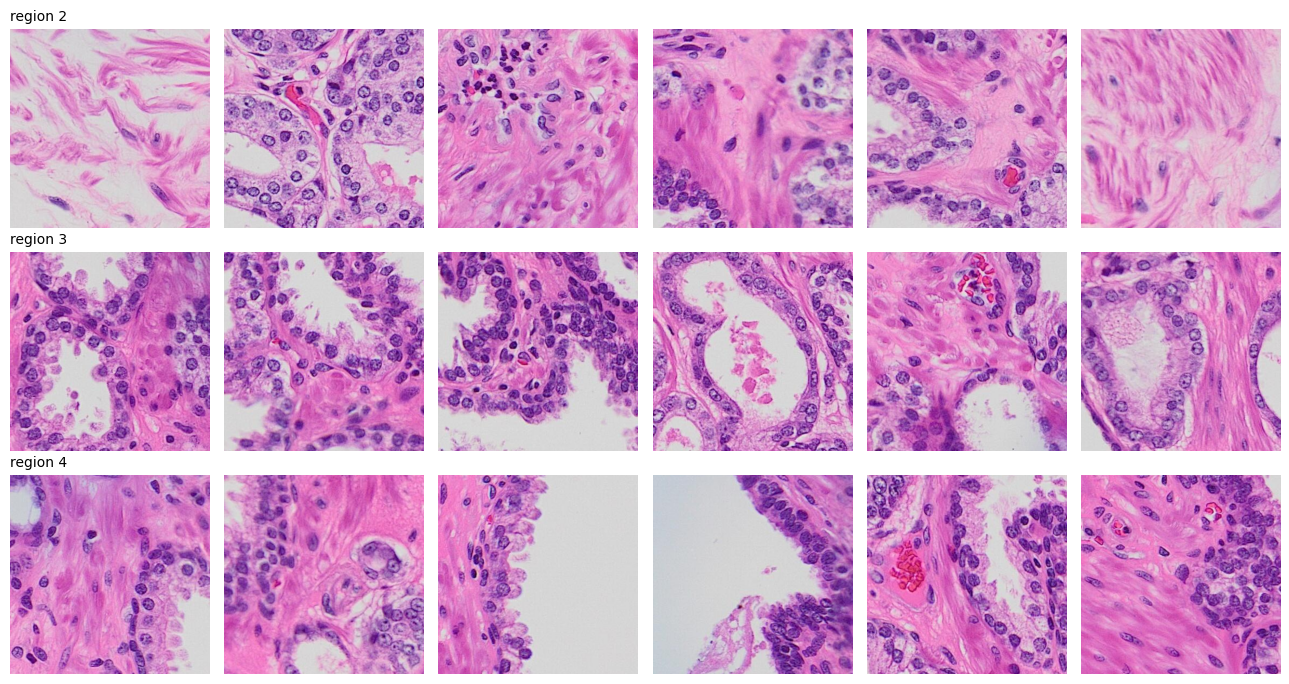

In [ ]:
rows = []
for rid, g in tiles[tiles.y == 1].groupby('region_id'):
    r = {'region_id': int(rid), 'tumor tiles': len(g)}
    for name, p in base.items():
        s = p[g.index.values]
        r[f'{name} mean score'] = round(s.mean(), 3)
        r[f'{name} share > 0.5'] = round((s > 0.5).mean(), 3)
    rows.append(r)
region_results = pd.DataFrame(rows).set_index('region_id')
display(region_results)
region_results.to_csv(os.path.join(ENC_DIR, 'check_regions.csv'))

reader0 = SlideReader(SLIDE, level=0)
fig, axes = plt.subplots(len(region_results), 6, figsize=(13, 2.3 * len(region_results)), squeeze=False)
for r_i, rid in enumerate(region_results.index):
    g = tiles[(tiles.y == 1) & (tiles.region_id == rid)].sample(min(6, (tiles.region_id == rid).sum()), random_state=SEED)
    for c in range(6):
        ax = axes[r_i, c]; ax.axis('off')
        if c < len(g):
            row = g.iloc[c]
            ax.imshow(reader0.read_box0(int(row.x0), int(row.y0), int(row.tile_px)))
    axes[r_i, 0].set_title(f'region {rid}', loc='left', fontsize=10)
reader0.close()
plt.tight_layout(); save_fig('region_samples'); plt.show()